# Chapter 2 · Trend and seasonality

*Book 21 · Time Series · Shelf V*

**Builds on:** [Chapter 1](01-time-as-an-index.ipynb) -- the hourly Zurich series in local time.
**You will:** see the daily, weekly and yearly cycles, take a series apart by hand with moving
averages, then with STL, and put a number on how seasonal it is.

Most series are a sum of a few simple movements: a slow **trend**, one or more repeating
**seasonal** patterns, and a **remainder** that is left when both are taken out. A forecast is
mostly the art of getting the first two right.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL

from ds_toolbox import io, viz

viz.use_style()
raw = io.load_sample("ewz_zurich_hourly.csv.gz")
load = (raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
        .tz_convert("Europe/Zurich").rename("MW"))
daily = load.resample("D").mean()

## Three cycles

A seasonal pattern is the average shape over one period. Electricity has three: the day (people
wake up), the week (offices close), and the year (heating and light).

an average weekday draws +22% more than a Sunday
January draws +12% more than July


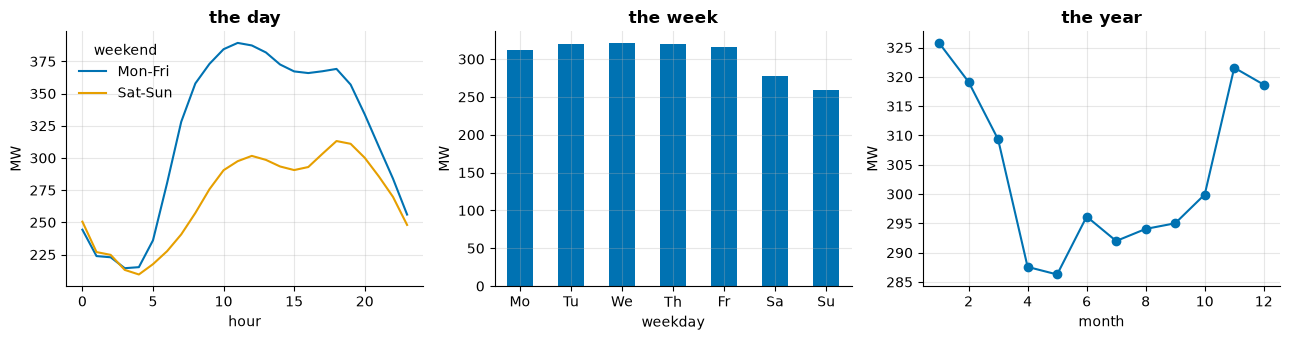

In [2]:
frame = load.to_frame().assign(hour=load.index.hour, weekday=load.index.day_of_week,
                               weekend=load.index.day_of_week >= 5, month=load.index.month)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
frame.groupby(["weekend", "hour"])["MW"].mean().unstack(0).rename(
    columns={False: "Mon-Fri", True: "Sat-Sun"}).plot(ax=axes[0], title="the day")
frame.groupby("weekday")["MW"].mean().plot.bar(ax=axes[1], title="the week", color=viz.PALETTE[0])
axes[1].set_xticklabels(["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"], rotation=0)
frame.groupby("month")["MW"].mean().plot(ax=axes[2], marker="o", title="the year")
for a in axes:
    a.set_ylabel("MW")
fig.tight_layout()

by_day = frame.groupby("weekday")["MW"].mean()
by_month = frame.groupby("month")["MW"].mean()
print(f"an average weekday draws {by_day[:5].mean() / by_day[6] - 1:+.0%} more than a Sunday")
print(f"January draws {by_month[1] / by_month[7] - 1:+.0%} more than July")

Any model that ignores one of these cycles leaves that much error on the table.

## A decomposition by hand

The classical recipe on the daily series, with a weekly season:

1. **Trend** -- a centred moving average over exactly one period (7 days) removes the weekly
   pattern, because every weekday appears once in each window.
2. **Seasonal** -- subtract the trend; the mean of what is left per weekday is the weekly shape.
3. **Remainder** -- whatever is left after both.

In [3]:
trend = daily.rolling(7, center=True).mean()
detrended = daily - trend
weekly_shape = detrended.groupby(daily.index.day_of_week).mean()
weekly_shape -= weekly_shape.mean()          # a seasonal component sums to zero over a period
seasonal = pd.Series(weekly_shape.reindex(daily.index.day_of_week).to_numpy(), index=daily.index)
remainder = daily - trend - seasonal
weekly_shape.round(1).set_axis(["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"])

Mo     8.7
Tu    16.4
We    17.1
Th    15.8
Fr    12.3
Sa   -26.4
Su   -43.9
Name: MW, dtype: float64

## STL

The hand recipe assumes the seasonal shape never changes. STL ("seasonal-trend decomposition by
Loess") lets it drift slowly and is robust to outliers. On the daily series with a weekly period:

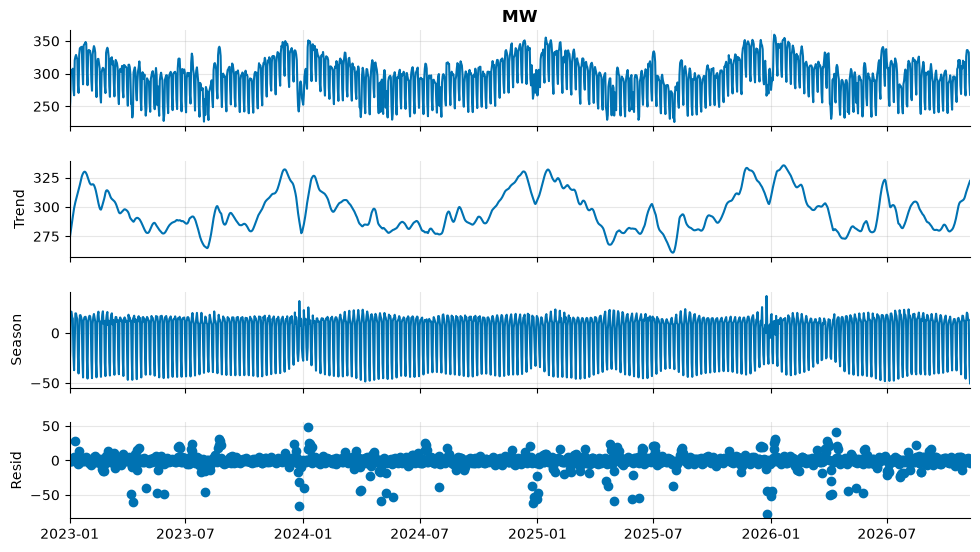

In [4]:
recent = daily["2023":]
stl = STL(recent, period=7, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(10, 6)

The "trend" here still carries the yearly cycle: with a 7-day period, STL treats everything
slower than a week as trend. On weekly means with a 52-week period the yearly cycle becomes the
season, and the trend is what is left: the long decline.

trend change 2017 -> 2026: -6.2%


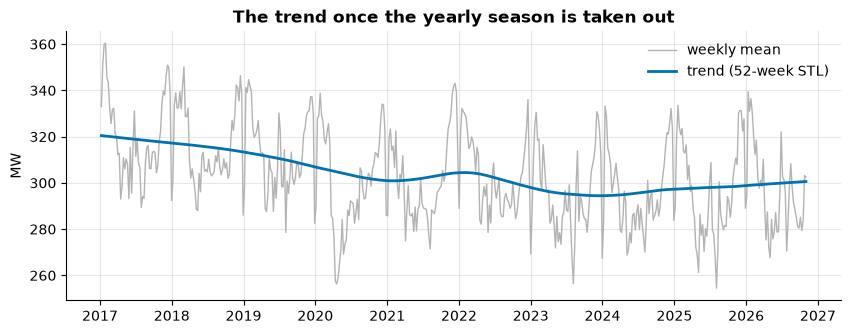

In [5]:
weekly = load.resample("W").mean().iloc[1:-1]
stl_y = STL(weekly, period=52, robust=True).fit()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(weekly, color="0.7", lw=1, label="weekly mean")
ax.plot(stl_y.trend, lw=2, label="trend (52-week STL)")
ax.set(ylabel="MW", title="The trend once the yearly season is taken out")
ax.legend()
change = stl_y.trend.iloc[-1] / stl_y.trend.iloc[0] - 1
print(f"trend change {weekly.index[0]:%Y} -> {weekly.index[-1]:%Y}: {change:+.1%}")

## How seasonal is it?

A useful single number (Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*,
§4.2): the strength of seasonality is

$$F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R)}{\operatorname{Var}(S + R)}\right)$$

Close to 1 means the remainder is small next to the season: a strongly seasonal series.

In [6]:
def strength(res):
    s, r = res.seasonal, res.resid
    return max(0.0, 1 - np.var(r) / np.var(s + r))

print(f"weekly season in daily data:  F_S = {strength(stl):.2f}")
print(f"yearly season in weekly data: F_S = {strength(stl_y):.2f}")

weekly season in daily data:  F_S = 0.81
yearly season in weekly data: F_S = 0.82


## What to remember

- Look for every cycle the generating process has: here the day, the week and the year.
- A moving average over exactly one period removes that period's season.
- STL generalises the recipe; its "trend" is everything slower than the period you give it.

## Exercises

1. Run STL on the *hourly* series of one month with `period=24`. How does the daily shape change
   between weekdays and the weekend, and does STL capture it?
2. Repeat the hand decomposition with a 14-day window. What goes wrong, and why?
3. Compute $F_S$ for NE5 and NE7 separately. Which network level is more weekly-seasonal?

**Next:** [Chapter 3 · Stationarity and autocorrelation](03-stationarity-and-autocorrelation.ipynb)